<a href="https://colab.research.google.com/github/Anil-Pradhan-web/VisionForge-AI/blob/main/YOLO11_trainning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Fri Sep 11 09:07:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.5 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
print("Ultralytics ready ✅")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics ready ✅


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive/visionforge-dataset"

data.yaml  test  train	valid


In [ ]:
!cat "/content/drive/MyDrive/visionforge-dataset/data.yaml"

path: .

train: train/images
val: valid/images
test: test/images

nc: 8

names:
  - capacitor
  - resistor
  - ic_chip
  - connector
  - screw
  - seal
  - battery_cell
  - gold_pin_connector

In [ ]:
!find "/content/drive/MyDrive/visionforge-dataset/train/images" -type f | wc -l

3393


In [ ]:
!find "/content/drive/MyDrive/visionforge-dataset/valid/images" -type f | wc -l

715


In [ ]:
!find "/content/drive/MyDrive/visionforge-dataset/test/images" -type f | wc -l

340


In [ ]:
!cp -r "/content/drive/MyDrive/visionforge-dataset" "/content/"

In [ ]:
!ls "/content/visionforge-dataset"

data.yaml  test  train	valid


In [ ]:
!cat "/content/visionforge-dataset/data.yaml"

path: .

train: train/images
val: valid/images
test: test/images

nc: 8

names:
  - capacitor
  - resistor
  - ic_chip
  - connector
  - screw
  - seal
  - battery_cell
  - gold_pin_connector

In [ ]:
from pathlib import Path

yaml_path = Path("/content/visionforge-dataset/data.yaml")
text = yaml_path.read_text()

text = text.replace("path: .", "path: /content/visionforge-dataset")

yaml_path.write_text(text)

print(yaml_path.read_text())

path: /content/visionforge-dataset

train: train/images
val: valid/images
test: test/images

nc: 8

names:
  - capacitor
  - resistor
  - ic_chip
  - connector
  - screw
  - seal
  - battery_cell
  - gold_pin_connector


In [ ]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/content/visionforge-dataset/data.yaml")
print("Dataset OK ✅")
print(data["train"])
print(data["val"])
print(data["names"])

Dataset OK ✅
/content/visionforge-dataset/train/images
/content/visionforge-dataset/valid/images
{0: 'capacitor', 1: 'resistor', 2: 'ic_chip', 3: 'connector', 4: 'screw', 5: 'seal', 6: 'battery_cell', 7: 'gold_pin_connector'}


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/visionforge-dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    project="/content/visionforge-runs",
    name="component_detector",
    exist_ok=True
)

Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visionforge-dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=component_detector, nbs=64, nms=None,

In [ ]:
!cp "/content/visionforge-runs/component_detector/weights/best.pt" \
"/content/drive/MyDrive/visionforge-component-detector-best.pt"

In [ ]:
!ls -lh "/content/drive/MyDrive/visionforge-component-detector-best.pt"

-rw------- 1 root root 5.3M Sep 11 11:50 /content/drive/MyDrive/visionforge-component-detector-best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/visionforge-component-detector-best.pt")

print("Model loaded ✅")
print(model.names)

Model loaded ✅
{0: 'capacitor', 1: 'resistor', 2: 'ic_chip', 3: 'connector', 4: 'screw', 5: 'seal', 6: 'battery_cell', 7: 'gold_pin_connector'}


In [ ]:
results = model.predict(
    source="/content/visionforge-dataset/test/images",
    conf=0.25,
    save=True,
    project="/content/visionforge-predictions",
    name="test",
    exist_ok=True
)

print("Prediction complete ✅")


image 1/340 /content/visionforge-dataset/test/images/-6001418491044938310_121_jpg.rf.eb3e6ca3db42246bf4f4ea9238fe8997.jpg: 640x480 1 battery_cell, 16.8ms
image 2/340 /content/visionforge-dataset/test/images/-6001418491044938311_121_jpg.rf.193b7ec17171e099d9078efe39ecbe07.jpg: 640x480 4 battery_cells, 17.9ms
image 3/340 /content/visionforge-dataset/test/images/-6001418491044938353_121_jpg.rf.3acefd4e30fb01c4572d08c339380044.jpg: 640x480 3 battery_cells, 13.2ms
image 4/340 /content/visionforge-dataset/test/images/-6001418491044938367_121_jpg.rf.75fcceac9ffcbbc074df7b673b42faec.jpg: 640x480 3 battery_cells, 21.0ms
image 5/340 /content/visionforge-dataset/test/images/-6001418491044938374_121_jpg.rf.422d68aa78c523168c59013c054fa717.jpg: 640x480 1 battery_cell, 11.2ms
image 6/340 /content/visionforge-dataset/test/images/-6001418491044938377_121_jpg.rf.b6d1fb9323d6a5196c70ae3bed7515d3.jpg: 640x480 3 battery_cells, 11.7ms
image 7/340 /content/visionforge-dataset/test/images/-60014184910449383

In [ ]:
import glob

pred_images = glob.glob("/content/visionforge-predictions/test/*")
print("Predicted files:", len(pred_images))
print(pred_images[:5])

Predicted files: 340
['/content/visionforge-predictions/test/image6_jpeg_jpg.rf.eea368322512fe9cac772f5e3674f4df.jpg', '/content/visionforge-predictions/test/-6001418491044938367_121_jpg.rf.75fcceac9ffcbbc074df7b673b42faec.jpg', '/content/visionforge-predictions/test/2678207_xl_jpg.rf.7579834b18d2845fb150509a692aff41.jpg', '/content/visionforge-predictions/test/IMG_1426_jpeg_jpg.rf.0f06f3f6f34147331332b8b432821ff8.jpg', '/content/visionforge-predictions/test/IMG_9526_grande_jpg.rf.02828015cb657e9932a1118eb1650e60.jpg']


detect_0197_20260327_151654_729_jpg.rf.8288491032f41cbeaa80a6d40cadd1dc.jpg


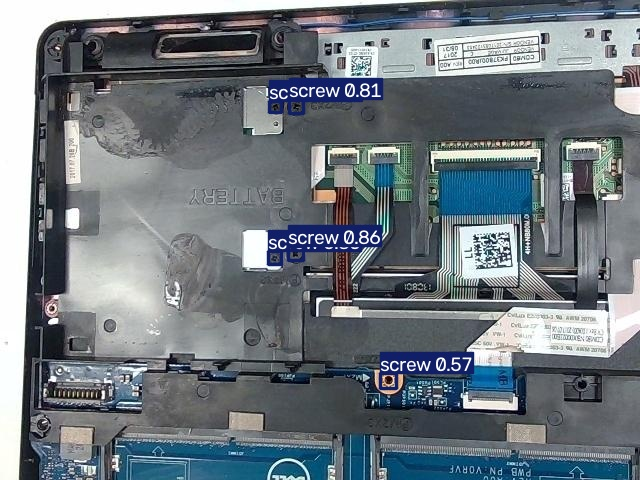

IMG_2224_jpeg_jpg.rf.5ab23c8c862ea46fb17c8739fd4efc60.jpg


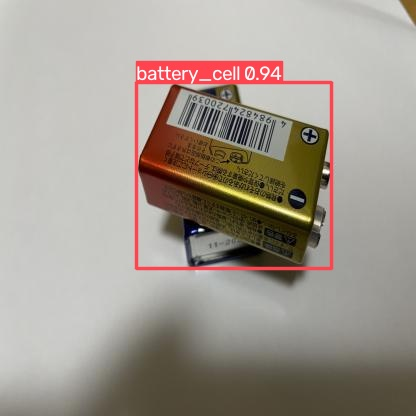

IMG_0926_jpeg_jpg.rf.58bab8803fa1df677a1950a909c30cc0.jpg


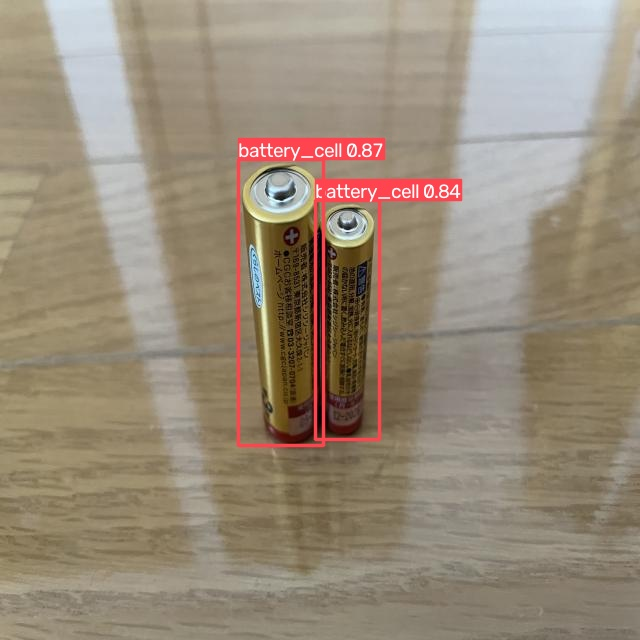

IMG_2167_jpeg_jpg.rf.6fdc4fb2f138f1b789936dc5ee4c39b9.jpg


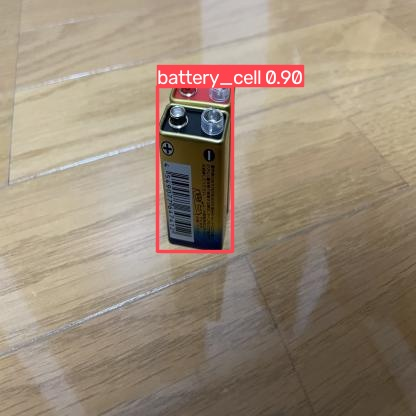

11_jpg.rf.7281853e4ba673d91e6ee37cc66deebf.jpg


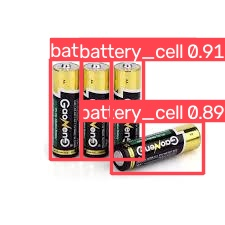

IMG_1861_jpeg_jpg.rf.988d40894ff2f369f31ee35a667b0f5d.jpg


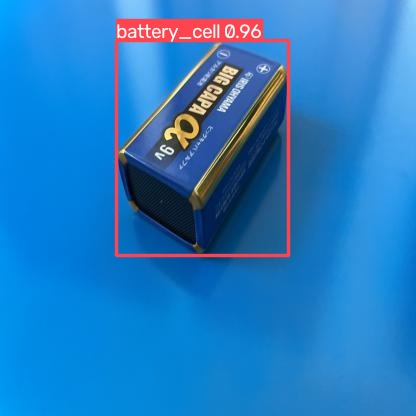

In [ ]:
from IPython.display import display
from PIL import Image
import glob
import random

pred_images = glob.glob(
    "/content/visionforge-predictions/test/*.jpg"
)

samples = random.sample(pred_images, 6)

for path in samples:
    print(path.split("/")[-1])
    display(Image.open(path))

In [ ]:
test_results = model.val(
    data="/content/visionforge-dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,583,712 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1487.6±719.5 MB/s, size: 218.3 KB)
val: Scanning /content/visionforge-dataset/test/labels... 340 images, 2 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 340/340 1.6Kit/s 0.2s
val: /content/visionforge-dataset/test/images/baterai-1-_jpeg_jpg.rf.1f824b64141b2f0bf5df588d1b5101dc.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/visionforge-dataset/test/images/detect_0250_20260327_170127_390_jpg.rf.1d3ded03db31dc602a95a87215ad49b2.jpg: 1 duplicate labels removed
val: /content/visionforge-dataset/test/images/pcb163rec1_jpg.rf.2c031e6be4f5a5e9eb64d653c87d7daf.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/visionforge-dataset/test/images/pcb163rec1_jpg.rf.44611f3dfa7e8d41e417b08e4f6f91c4.jpg: ignoring corrup

In [ ]:
print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Test mAP50: 0.50244095916335
Test mAP50-95: 0.33060600924215044


In [ ]:
print(test_results.names)
print("Per-class mAP50:", test_results.box.maps)

{0: 'capacitor', 1: 'resistor', 2: 'ic_chip', 3: 'connector', 4: 'screw', 5: 'seal', 6: 'battery_cell', 7: 'gold_pin_connector'}
Per-class mAP50: [   0.026536    0.012905     0.36242    0.016412     0.60844     0.52785     0.75967     0.33061]


In [ ]:
from pathlib import Path

test_labels = Path("/content/visionforge-dataset/test/labels")

for f in sorted(test_labels.glob("*.txt")):
    lines = f.read_text(errors="ignore").splitlines()
    for line in lines:
        parts = line.split()
        if len(parts) not in (5,):
            print("MIXED/INVALID:", f.name, "->", len(parts), "values")
            break

MIXED/INVALID: -6001418491044938310_121_jpg.rf.eb3e6ca3db42246bf4f4ea9238fe8997.txt -> 11 values
MIXED/INVALID: -6001418491044938311_121_jpg.rf.193b7ec17171e099d9078efe39ecbe07.txt -> 11 values
MIXED/INVALID: 102_jpg.rf.db5e01dd8fceaa6b0fa8180ada411b61.txt -> 11 values
MIXED/INVALID: 105_png_jpg.rf.aa3eb32dc5cb9537b807a2e76557e512.txt -> 11 values
MIXED/INVALID: 127_jpg.rf.65c550bbcf3c51a68bfcb8705a193a54.txt -> 11 values
MIXED/INVALID: 29_jpg.rf.f7898d9bdae4d35c61b686831a0d8d21.txt -> 13 values
MIXED/INVALID: 2_jpg.rf.0501640deaed90cb7abc37346566c842.txt -> 11 values
MIXED/INVALID: IMG_0906_jpeg_jpg.rf.da8afadca4cab62a6e8f63b07e776a4b.txt -> 37 values
MIXED/INVALID: IMG_0931_jpeg_jpg.rf.14c0178c1b34416a11a54e99ebb910ed.txt -> 29 values
MIXED/INVALID: IMG_0936_jpeg_jpg.rf.268f05b570f1c11f0009a19d492aabd5.txt -> 29 values
MIXED/INVALID: IMG_0937_jpeg_jpg.rf.e830819ccb12c55636bdb9269081a4b2.txt -> 25 values
MIXED/INVALID: IMG_0941_jpeg_jpg.rf.65ba370a78527fdc3bf2d99133b40216.txt -> 21 va

In [ ]:
from pathlib import Path

for f in sorted(test_labels.glob("*.txt")):
    lines = f.read_text(errors="ignore").splitlines()
    for i, line in enumerate(lines, 1):
        if len(line.split()) != 5:
            print(f"{f.name}: line {i} -> {line}")

-6001418491044938310_121_jpg.rf.eb3e6ca3db42246bf4f4ea9238fe8997.txt: line 1 -> 6 0.16369981791897292 0.3447580649750096 0.4312926139847579 0.5418892802231309 0.4312926139847579 0.5418892802231308 0.731747856229145 0.31307625400691225 0.4782388747954817 0.12298532857578208
-6001418491044938311_121_jpg.rf.193b7ec17171e099d9078efe39ecbe07.txt: line 1 -> 6 0.016229152679443595 0.4926427900791168 0.08858592784400666 0.6298943040653405 0.08858592784400673 0.6298943040653405 0.29984346538130635 0.47148530884739925 0.18717326637981332 0.3306772468508451
-6001418491044938311_121_jpg.rf.193b7ec17171e099d9078efe39ecbe07.txt: line 2 -> 6 0.24539581934611027 0.5981115400791168 0.44537642861687937 0.415162036350741 0.558047263729329 0.5031670601929508 0.34209522733314823 0.7002985139312549
-6001418491044938311_121_jpg.rf.193b7ec17171e099d9078efe39ecbe07.txt: line 3 -> 6 0.7646103024077474 0.6298943040653405 0.9570901625650007 0.44684390694138393 0.9570901625650005 0.4468439069413842 0.6848019134738

In [ ]:
from pathlib import Path

ROOT = Path("/content/visionforge-dataset")

for split in ["train", "valid", "test"]:
    bad = 0
    total = 0

    for f in (ROOT / split / "labels").glob("*.txt"):
        for line in f.read_text(errors="ignore").splitlines():
            if line.strip():
                total += 1
                if len(line.split()) != 5:
                    bad += 1

    print(f"{split}: {bad} non-detection rows / {total} total rows")

train: 1966 non-detection rows / 59763 total rows
valid: 754 non-detection rows / 11236 total rows
test: 63 non-detection rows / 5673 total rows


In [ ]:
from pathlib import Path

ROOT = Path("/content/visionforge-dataset")

for split in ["train", "valid", "test"]:
    files = []
    for f in (ROOT / split / "labels").glob("*.txt"):
        if any(len(line.split()) != 5 for line in f.read_text(errors="ignore").splitlines() if line.strip()):
            files.append(f.name)

    print(f"\n{split}: {len(files)} affected label files")


train: 356 affected label files

valid: 106 affected label files

test: 32 affected label files


In [ ]:
from pathlib import Path

ROOT = Path("/content/visionforge-dataset")

def polygon_to_bbox(parts):
    cls = parts[0]
    coords = list(map(float, parts[1:]))

    xs = coords[0::2]
    ys = coords[1::2]

    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)

    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    width = x_max - x_min
    height = y_max - y_min

    return f"{cls} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}"

for split in ["train", "valid", "test"]:
    label_dir = ROOT / split / "labels"
    converted = 0

    for label_file in label_dir.glob("*.txt"):
        lines = label_file.read_text(errors="ignore").splitlines()
        new_lines = []

        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue

            if len(parts) == 5:
                new_lines.append(" ".join(parts))
            elif len(parts) > 5 and (len(parts) - 1) % 2 == 0:
                new_lines.append(polygon_to_bbox(parts))
                converted += 1
            else:
                print("SKIPPED INVALID:", split, label_file.name, line)

        label_file.write_text(
            "\n".join(new_lines) + ("\n" if new_lines else ""),
            encoding="utf-8"
        )

    print(f"{split}: converted {converted} polygon annotations")

train: converted 1966 polygon annotations
valid: converted 754 polygon annotations
test: converted 63 polygon annotations


In [ ]:
for split in ["train", "valid", "test"]:
    bad = 0
    total = 0

    for f in (ROOT / split / "labels").glob("*.txt"):
        for line in f.read_text(errors="ignore").splitlines():
            if line.strip():
                total += 1
                if len(line.split()) != 5:
                    bad += 1

    print(f"{split}: {bad} non-detection rows / {total} total rows")

train: 0 non-detection rows / 59763 total rows
valid: 0 non-detection rows / 11236 total rows
test: 0 non-detection rows / 5673 total rows


In [ ]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/content/visionforge-dataset/data.yaml")
print("Clean dataset check ✅")
print(data["train"])
print(data["val"])
print(data["test"])

Clean dataset check ✅
/content/visionforge-dataset/train/images
/content/visionforge-dataset/valid/images
/content/visionforge-dataset/test/images


In [ ]:
from pathlib import Path

for split in ["train", "valid", "test"]:
    images = list((Path("/content/visionforge-dataset") / split / "images").glob("*"))
    labels = list((Path("/content/visionforge-dataset") / split / "labels").glob("*.txt"))
    print(f"{split}: {len(images)} images | {len(labels)} labels")

train: 3393 images | 3393 labels
valid: 715 images | 715 labels
test: 340 images | 340 labels


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/visionforge-dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    project="/content/visionforge-runs",
    name="component_detector_clean",
    exist_ok=True
)